# No 2. Bangladesh Crime Dataset rape, murder, assault).




Bangladesh Crime Dataset:
a.	incident_month = The month when the incident occurred
b.	incident_week = The week number within the month when the incident occurred
c.	incident_weekday = The day of the week when the incident occurred
d.	weekend = Indicates whether the incident occurred on a weekend
e.	part_of_the_day = The time of day when the incident occurred (e.g., morning, afternoon, evening, night)
f.	incident_district = Administrative district of the incident location.
g.	incident_division = Higher-level administrative division (e.g., city or province) of the incident location.
h.	precip = Precipitation level (mm) on the day of the incident.
i.	visibility = Visibility distance (usually in km) on the day of the incident.
j.	heatindex = Heat index value (combining temperature and humidity) on the day of the incident to indicate how hot it felt.
k.	season = Season when the incident occurred
l.	male_population = Number of males in the area.
m.	female_population = Number of females in the area.
n.	total_population = Total population in the area.
o.	gender_ration = Sex ratio, expressed as the number of males per 100 females or vice versa.
p.	average_household_size  Average number of people per household in the area.
q.	density_per_kmsq = Population density per square kilometer in the area.
r.	literacy_rate = Percentage of literate people in the area.
s.	religious_institution = Number of religious institutions in the area (e.g., mosques, churches, temples).
t.	playground = Number of playgrounds in the area.
u.	park = Number of public parks in the area.
v.	police_station = Number of police stations in the area.
w.	school = Number of schools (primary to high school) in the area.
x.	college = Number of colleges or universities in the area.
y.	crime = Indicating the category of crime (e.g., rape, murder, assault).


#### import Libraries

In [1]:
import numpy as np
import pandas as pd

# buat vis
import matplotlib.pyplot as plt
import seaborn as sns

# buat preprocessing sm model
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

#### load dataset

In [3]:
df = pd.read_csv("Bangladesh_Crime_Dataset_A.csv", sep=",", index_col=0) #header kolom pertama yg "," itu index
df.head()

,incident_month,incident_week,incident_weekday,weekend,part_of_the_day,incident_district,incident_division,precip,visibility,heatindex,...,average_household_size,density_per_kmsq,literacy_rate,religious_institution,playground,park,police_station,school,college,crime
0,7.0,29,wednesday,0,morning,dhaka,dhaka,6.1,10,32,...,8.42,30551.0,74.6,4289,99,17,60,242,64,murder
1,1.0,2,wednesday,0,night,dhaka,dhaka,0.0,10,22,...,8.42,30551.0,74.6,4289,99,17,60,242,64,murder
2,1.0,4,tuesday,0,night,dhaka,dhaka,0.0,10,25,...,8.42,30551.0,74.6,4289,99,17,60,242,64,murder
3,3.0,9,friday,1,night,dhaka,dhaka,0.0,10,30,...,8.42,30551.0,74.6,4289,99,17,60,242,64,murder
4,8.0,34,thursday,0,night,dhaka,dhaka,21.9,9,38,...,8.42,30551.0,74.6,4289,99,17,60,242,64,murder


In [4]:
df.shape

(6574, 25)

In [5]:
df.dtypes #cek tipe data per column
#semua datatype sudah keliatan akurat, tidak ada dttype yg ga sesuai

,0
incident_month,float64
incident_week,int64
incident_weekday,object
weekend,int64
part_of_the_day,object
incident_district,object
incident_division,object
precip,float64
visibility,int64
heatindex,int64


## 1. Data Preprocessing & EDA

In [6]:
df.describe(include="all") #stats cepet semua kolom, numeric, kategorik, datetime

,incident_month,incident_week,incident_weekday,weekend,part_of_the_day,incident_district,incident_division,precip,visibility,heatindex,...,average_household_size,density_per_kmsq,literacy_rate,religious_institution,playground,park,police_station,school,college,crime
count,5917.000000,6574.000000,6574,6574.000000,6457,6246,6574,6574.000000,6574.000000,6574.000000,...,6574.000000,6.574000e+03,6246.000000,6574.00000,6574.000000,6574.000000,6574.000000,6574.000000,6574.000000,6574
unique,NaN,NaN,7,NaN,5,64,192,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6
top,NaN,NaN,tuesday,NaN,night,dhaka,dhaka,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,murder
freq,NaN,NaN,1010,NaN,3179,1115,1806,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1518
mean,6.210749,25.193946,NaN,0.273806,NaN,NaN,NaN,6.187998,9.488287,31.597657,...,4.965023,1.891212e+52,55.742683,1232.03164,42.504411,3.863706,11.762093,75.218893,15.479617,NaN
std,3.319075,14.517965,NaN,0.445944,NaN,NaN,NaN,11.989998,0.922742,5.502593,...,1.422850,1.354499e+54,12.082504,1245.17044,44.857967,5.883186,19.604510,71.743767,19.721917,NaN
min,1.000000,1.000000,NaN,0.000000,NaN,NaN,NaN,0.000000,4.000000,15.000000,...,3.580000,5.615431e-61,26.700000,0.00000,0.000000,0.000000,-1.000000,1.000000,0.000000,NaN
25%,3.000000,13.000000,NaN,0.000000,NaN,NaN,NaN,0.000000,9.000000,27.000000,...,4.110000,9.100000e+02,46.600000,519.00000,5.000000,0.000000,2.000000,30.000000,4.000000,NaN
50%,6.000000,25.000000,NaN,0.000000,NaN,NaN,NaN,0.800000,10.000000,33.000000,...,4.440000,1.239000e+03,53.900000,818.00000,25.000000,1.000000,3.000000,45.000000,8.000000,NaN
75%,9.000000,37.000000,NaN,1.000000,NaN,NaN,NaN,7.500000,10.000000,36.000000,...,5.100000,4.318000e+03,67.200000,1125.00000,78.000000,3.000000,6.000000,86.000000,15.000000,NaN


In [7]:
#cek missing values

missing = df.isna().sum().sort_values(ascending=False)
missing

,0
incident_month,657
incident_district,328
literacy_rate,328
part_of_the_day,117
incident_weekday,0
weekend,0
incident_division,0
precip,0
incident_week,0
visibility,0


In [8]:
#langsung replace missing
#numeric --> pake median --> tidak se-sensitif mean dengan skew ato outliers
#categorik --> pake mode

num_cols = df.select_dtypes(include=["int64", "float64"]).columns #karena dtype udah bener, langsung dari select aja
cat_cols = df.select_dtypes(include=["object", "bool"]).columns

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

In [9]:
#cek duplicate values
df.duplicated().sum() #karena hasilnya relatif kecil dibanding seluruh struktur dataset, maka di omit aja
df = df.drop_duplicates()

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
#cek unique values, karena ada index, automatis setiap row unique, cek uniqueness in column per variabelnya

df.index.name
unique_counts = df.nunique().sort_values(ascending = False)
unique_counts
#jika data numerik, wajar kalau banyak unique values karena nilai continuous data bisa banyak
#jika data kategorik, harusnya tidak sebanyak unique values data numeric
# data biner cuman ada 2 unique values

,0
density_per_kmsq,515
precip,475
male_population,455
female_population,455
total_population,455
religious_institution,378
literacy_rate,264
incident_division,192
average_household_size,164
playground,106


In [12]:
#cek unique values buat categorical column

cat_cols = df.select_dtypes(include=["object", "bool"]).columns

for col in cat_cols:
    print(f"\nColumn: {col}")
    print(df[col].unique())

#dari hasilnya
#incident_weekday = consisten sama spelling sudah benar
# part_of_the_day = consistent & spelling benar
#incident_district = karena district bisa banyak, unique values memang banyak, tapi sudah consistent (no whitespace)
#incident_division = MASALAH DISINI, spelling udah bener, tapi banyak capitalisation aneh --> solusi di lower semua
#season = consistent & spelling benar
#crime = consistent & spelling benar


Column: incident_weekday
['wednesday' 'tuesday' 'friday' 'thursday' 'sunday' 'saturday' 'monday']

Column: part_of_the_day
['morning' 'night' 'evening' 'noon' 'afternoon']

Column: incident_district
['dhaka' 'gazipur' 'chattogram' 'rajshahi' 'khulna' 'sirajganj'
 'narsingdi' 'lakshmipur' 'manikganj' 'patuakhali' 'jashore' 'sunamganj'
 'bhola' 'satkhira' 'gopalganj' 'habiganj' 'rangpur' 'tangail' 'sylhet'
 'dinajpur' 'kurigram' 'rangamati' 'lalmonirhat' 'barisal' 'brahmanbaria'
 'joypurhat' 'chuadanga' 'bandarban' 'barguna' 'narayanganj' 'pabna'
 'netrokona' 'panchagarh' 'kishoreganj' 'bagerhat' 'rajbari' 'natore'
 'moulvibazar' 'noakhali' 'mymensingh' 'pirojpur' 'faridpur' 'kushtia'
 'chapainawabganj' 'bogura' 'jamalpur' 'comilla' 'coxsbazar' 'feni'
 'khagrachhari' 'nilphamari' 'chandpur' 'gaibandha' 'meherpur' 'jhenaidah'
 'thakurgaon' 'narail' 'jhalakathi' 'munshiganj' 'madaripur' 'magura'
 'naogaon' 'sherpur' 'shariatpur']

Column: incident_division
['dhaka' 'DHAKA' 'Dhaka' '  dhak

In [13]:
# perbaikin inconsistencies di incident_division
#for col in cat_cols:
#    df[col] = df[col].str.lower().str.strip()

for col in cat_cols:
    df.loc[:, col] = df[col].str.lower().str.strip()

for col in cat_cols:
    print(f"\nColumn: {col}")
    print(df[col].unique())


Column: incident_weekday
['wednesday' 'tuesday' 'friday' 'thursday' 'sunday' 'saturday' 'monday']

Column: part_of_the_day
['morning' 'night' 'evening' 'noon' 'afternoon']

Column: incident_district
['dhaka' 'gazipur' 'chattogram' 'rajshahi' 'khulna' 'sirajganj'
 'narsingdi' 'lakshmipur' 'manikganj' 'patuakhali' 'jashore' 'sunamganj'
 'bhola' 'satkhira' 'gopalganj' 'habiganj' 'rangpur' 'tangail' 'sylhet'
 'dinajpur' 'kurigram' 'rangamati' 'lalmonirhat' 'barisal' 'brahmanbaria'
 'joypurhat' 'chuadanga' 'bandarban' 'barguna' 'narayanganj' 'pabna'
 'netrokona' 'panchagarh' 'kishoreganj' 'bagerhat' 'rajbari' 'natore'
 'moulvibazar' 'noakhali' 'mymensingh' 'pirojpur' 'faridpur' 'kushtia'
 'chapainawabganj' 'bogura' 'jamalpur' 'comilla' 'coxsbazar' 'feni'
 'khagrachhari' 'nilphamari' 'chandpur' 'gaibandha' 'meherpur' 'jhenaidah'
 'thakurgaon' 'narail' 'jhalakathi' 'munshiganj' 'madaripur' 'magura'
 'naogaon' 'sherpur' 'shariatpur']

Column: incident_division
['dhaka' 'gazipur' 'chattogram' 

In [15]:
#cek berapa yang distinct unique values & datatypenya
uniqueness_summary = pd.DataFrame({
    "Unique Values": df.nunique(),
    "Data Type": df.dtypes
}).sort_values("Unique Values")

uniqueness_summary


,Unique Values,Data Type
weekend,2,int64
season,3,object
part_of_the_day,5,object
crime,6,object
visibility,7,int64
incident_weekday,7,object
incident_division,9,object
park,11,int64
incident_month,12,float64
police_station,18,int64


In [56]:
#buat numerical data, fix outliers, but keep extreme values
#keep extreme values karena hal itu bisa tetap valid, hanya fitur, cause atau multivariabel extremes
#beberapa numerical data itu sbnernya categorical, tp data typenya numeric, kyk weekends yang sbnernya binary tp int64

#column yg categorical with datattype numeric
#weekend = binary 0/1
#incident_month = bulan januari-december (1-12)
#incident_week = minggu ada 4 per bulan
#gender_ration = data discrete, less likely for outliers, but can be inconsistent

# Columns selected for outlier handling
outlier_cols = [
    "precip", "visibility", "heatindex",
    "male_population", "female_population", "total_population",
    "density_per_kmsq", "average_household_size", "literacy_rate",
    "religious_institution", "playground", "park",
    "police_station", "school", "college"
]

# Make sure we are not working on a view
df = df.copy()

for col in outlier_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    lowext = Q1 - 3.0 * IQR
    upext = Q3 + 3.0 * IQR

    median = df[col].median()

    # Replace ONLY mild outliers
    df.loc[
        ((df[col] < lower) & (df[col] >= lowext)) |
        ((df[col] > upper) & (df[col] <= upext)),
        col
    ] = median


In [58]:
for col in outlier_cols:
    print(
        col,
        ":",
        ((df[col] < lower) | (df[col] > upper)).sum(),
        "outliers handled"
    )

precip : 260 outliers handled
visibility : 0 outliers handled
heatindex : 3549 outliers handled
male_population : 6306 outliers handled
female_population : 6306 outliers handled
total_population : 6306 outliers handled
density_per_kmsq : 0 outliers handled
average_household_size : 0 outliers handled
literacy_rate : 6213 outliers handled
religious_institution : 6295 outliers handled
playground : 2652 outliers handled
park : 0 outliers handled
police_station : 834 outliers handled
school : 4740 outliers handled
college : 833 outliers handled


In [53]:
#buat numerical tapi merepresentasikan sebuah kategori, spt bulan, weekends, cek aja kalo input valuesnya bener eg. gaada bulan 13

df["weekend"].unique() #hasil udah aman eithr 0 or 1

array([0, 1])

In [54]:
sorted(df["incident_month"].unique()) #hasil udah aman 1-12

[np.float64(1.0),
 np.float64(2.0),
 np.float64(3.0),
 np.float64(4.0),
 np.float64(5.0),
 np.float64(6.0),
 np.float64(7.0),
 np.float64(8.0),
 np.float64(9.0),
 np.float64(10.0),
 np.float64(11.0),
 np.float64(12.0)]

In [55]:
sorted(df["incident_week"].unique()) #ternyata ini weeks in a year, jadi emang ~53 unique values

[np.int64(1),
 np.int64(2),
 np.int64(3),
 np.int64(4),
 np.int64(5),
 np.int64(6),
 np.int64(7),
 np.int64(8),
 np.int64(9),
 np.int64(10),
 np.int64(11),
 np.int64(12),
 np.int64(13),
 np.int64(14),
 np.int64(15),
 np.int64(16),
 np.int64(17),
 np.int64(18),
 np.int64(19),
 np.int64(20),
 np.int64(21),
 np.int64(22),
 np.int64(23),
 np.int64(24),
 np.int64(25),
 np.int64(26),
 np.int64(27),
 np.int64(28),
 np.int64(29),
 np.int64(30),
 np.int64(31),
 np.int64(32),
 np.int64(33),
 np.int64(34),
 np.int64(35),
 np.int64(36),
 np.int64(37),
 np.int64(38),
 np.int64(39),
 np.int64(40),
 np.int64(41),
 np.int64(42),
 np.int64(43),
 np.int64(44),
 np.int64(45),
 np.int64(46),
 np.int64(47),
 np.int64(48),
 np.int64(49),
 np.int64(50),
 np.int64(51),
 np.int64(52),
 np.int64(53)]

In [21]:
sorted(df["gender_ration"].unique())

[np.int64(84),
 np.int64(85),
 np.int64(86),
 np.int64(87),
 np.int64(88),
 np.int64(89),
 np.int64(90),
 np.int64(91),
 np.int64(92),
 np.int64(93),
 np.int64(94),
 np.int64(95),
 np.int64(96),
 np.int64(97),
 np.int64(98),
 np.int64(99),
 np.int64(100),
 np.int64(101),
 np.int64(102),
 np.int64(103),
 np.int64(104),
 np.int64(105),
 np.int64(106),
 np.int64(107),
 np.int64(108),
 np.int64(109),
 np.int64(110),
 np.int64(111),
 np.int64(113),
 np.int64(114),
 np.int64(116),
 np.int64(117),
 np.int64(125),
 np.int64(203)]

### KESIMPULAN PREPROCESSING

MISSING VALUES

numerical --> impute pake median

categorical --> impute pake mode


DUPLICATE VALUES

--> no duplicate values found


UNIQUE VALUES / INCONSISTENCIES

numerical --> wajar ada banyak karena data bisa continuous/ measured by a unit

categoric (tapi di representasikan secara numeric) --> data kategorik tidak sebanyak unique values data numeric

binary --> weekend [0/1] cuman 2 unique values


categorical columsn

- incident_weekday = consisten sama spelling sudah benar
- part_of_the_day = consistent & spelling benar
- incident_district = karena district bisa banyak, unique values memang banyak, tapi sudah consistent (no whitespace)
 - incident_division = MASALAH DISINI, spelling udah bener, tapi banyak capitalisation aneh --> solusi di lower semua
- season = consistent & spelling benar
- crime = consistent & spelling benar

OUTLIERS & EXTREME VALUES
- numerical --> replace outliers with median(ngga sensitive terhadap skewed data)
keep extreme values karena hal itu bisa tetap valid, hanya fitur, cause atau multivariabel extremes

beberapa numerical data, sebenernya categorical, tp data typenya numeric, kyk weekends yang sbnernya binary tp int64

### Masuk Visualisasi

In [61]:
#cek frequency tables buat categorical columns
#paling sering ada reported crime di kondisi apa --> hari apa

for col in cat_cols:
    print(f"\nFrequency table for {col}:")
    print(df[col].value_counts())



Frequency table for incident_weekday:
incident_weekday
tuesday      971
wednesday    931
monday       929
thursday     911
saturday     873
friday       852
sunday       839
Name: count, dtype: int64

Frequency table for part_of_the_day:
part_of_the_day
night        3151
morning      1886
noon          484
evening       465
afternoon     320
Name: count, dtype: int64

Frequency table for incident_district:
incident_district
dhaka         1391
chattogram     455
mymensingh     244
jashore        233
dinajpur       186
              ... 
magura          14
sherpur         13
shariatpur      11
kurigram        10
narail           9
Name: count, Length: 64, dtype: int64

Frequency table for incident_division:
incident_division
dhaka         1955
chattogram    1020
rajshahi       739
rangpur        680
khulna         671
mymensingh     438
sylhet         403
barisal        396
gazipur          4
Name: count, dtype: int64

Frequency table for season:
season
rainy     2722
winter    1860
hot

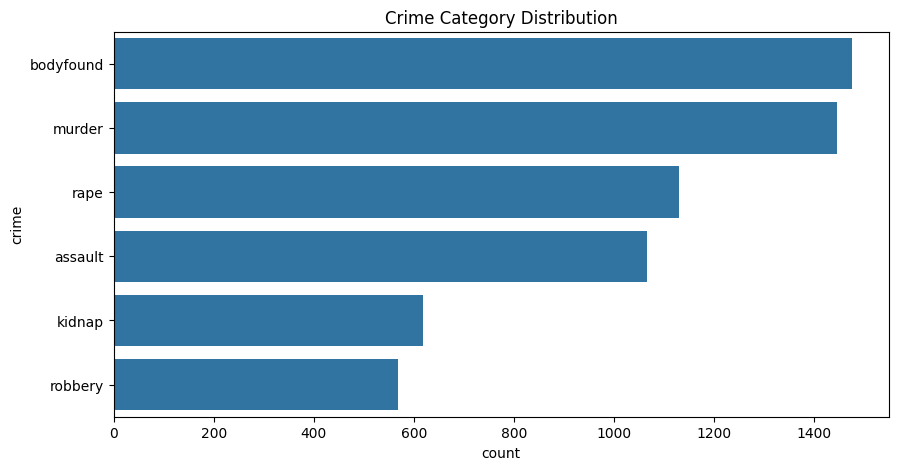

In [22]:
#visualisasi target var y = crime
#cek kalau distribusi simetris attau ngga & balanced
#karena ini UNSUPERVISED CLUSTERING, maka variabel ini hanya untuk profiling tapi sama pentingnya

#mengapa unsupervised clustering --> karena kita mengelompokan data points dengan fitur atau characteristics yang mirip, sebelum adanya LABELED DATA
# bertujuan untuk mencari cluster yang terbentuk secara natural karena pola tertentu

plt.figure(figsize=(10,5))
sns.countplot(y="crime", data=df, order=df["crime"].value_counts().index)
plt.title("Crime Category Distribution")
plt.show()

#bodyfound paling tinggi, diikuti murder
#robbery paling kecil

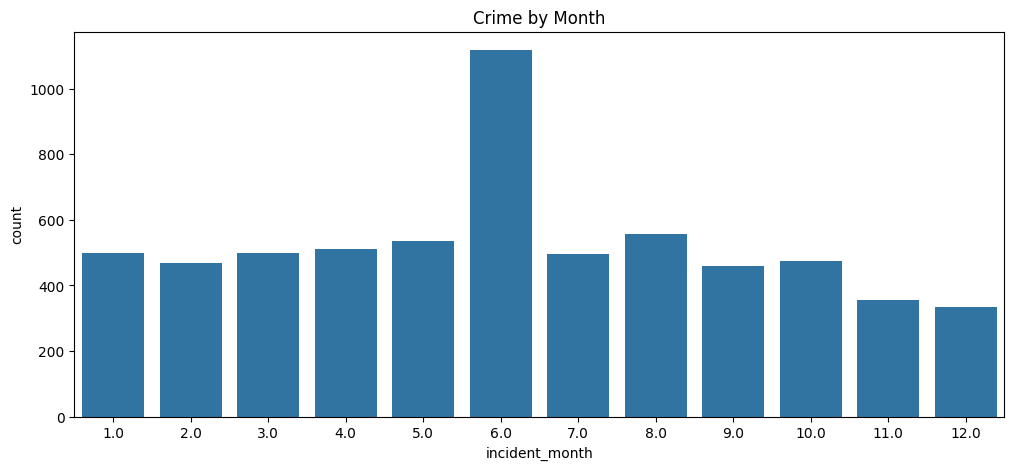

In [23]:
#liat jumlah crime per bulannya, apa ada value yg aneh?

plt.figure(figsize=(12,5))
sns.countplot(x="incident_month", data=df)
plt.title("Crime by Month")
plt.show()
#crime di bulan 6 --> Juni sangat tinggi
#crime di bulan 12 --> december paling rendah

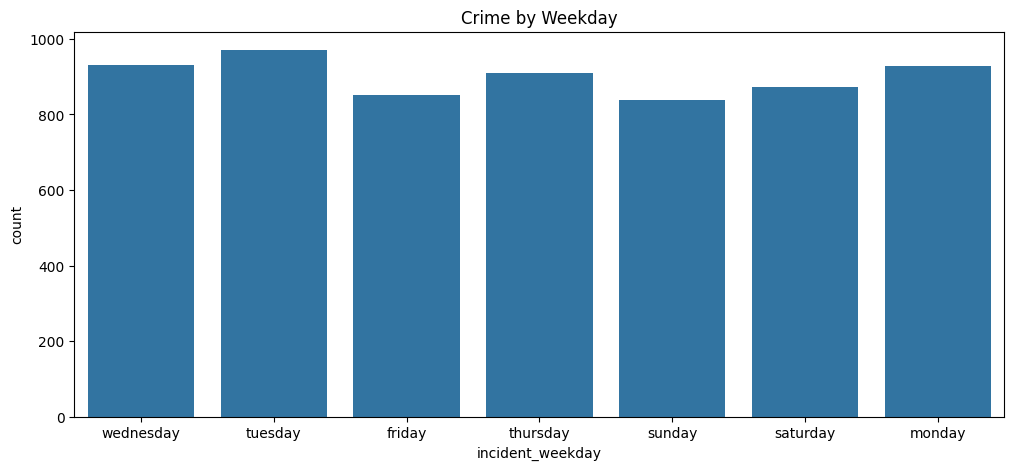

In [24]:
#jumlah crime per harinya

plt.figure(figsize=(12,5))
sns.countplot(x="incident_weekday", data=df)
plt.title("Crime by Weekday")
plt.show()

#figur memperlihatkan count crime relatif stabil

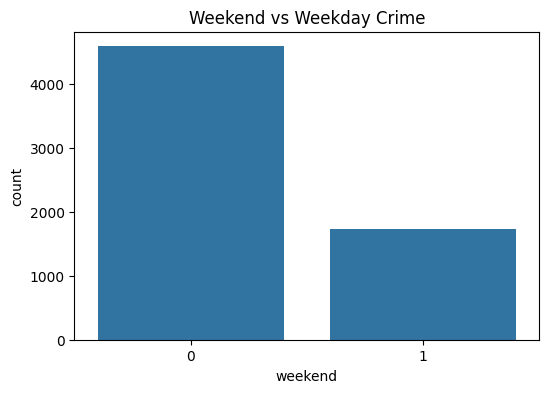

In [25]:
#crime lbh sering di weekend atau weekdays

plt.figure(figsize=(6,4))
sns.countplot(x="weekend", data=df)
plt.title("Weekend vs Weekday Crime")
plt.show()

#crime lebih banyak di weekend = 0 --> maka weekdays

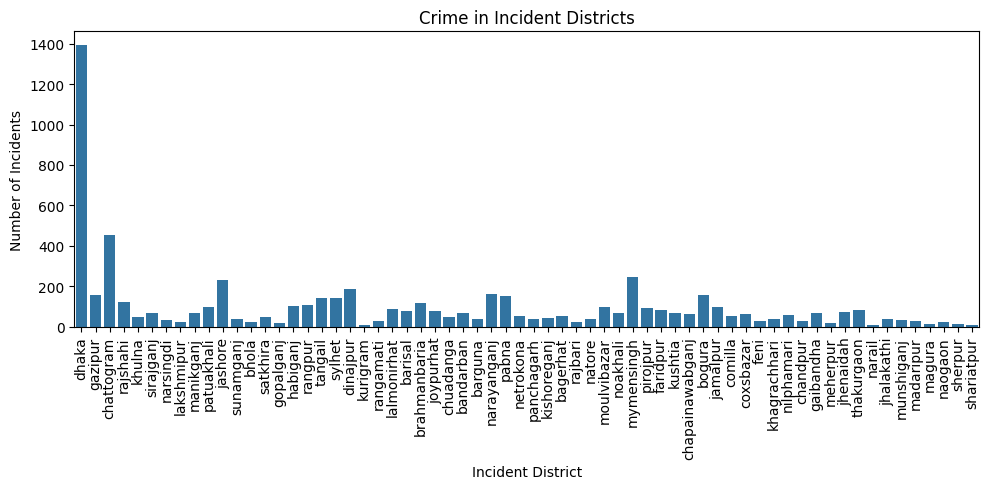

In [26]:
#jumlah crime di incident_district
plt.figure(figsize=(10,5))
sns.countplot(x="incident_district", data=df)
plt.title("Crime in Incident Districts")
plt.xlabel("Incident District")
plt.ylabel("Number of Incidents")

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

#dhakza paling banyak crimes

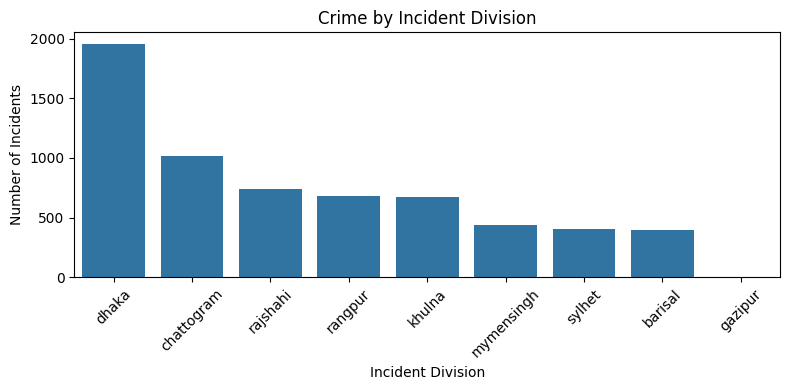

In [27]:
#jumlah crime di incident_division
plt.figure(figsize=(8,4))
sns.countplot(
    x="incident_division",
    data=df,
    order=df["incident_division"].value_counts().index
)
plt.title("Crime by Incident Division")
plt.xlabel("Incident Division")
plt.ylabel("Number of Incidents")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

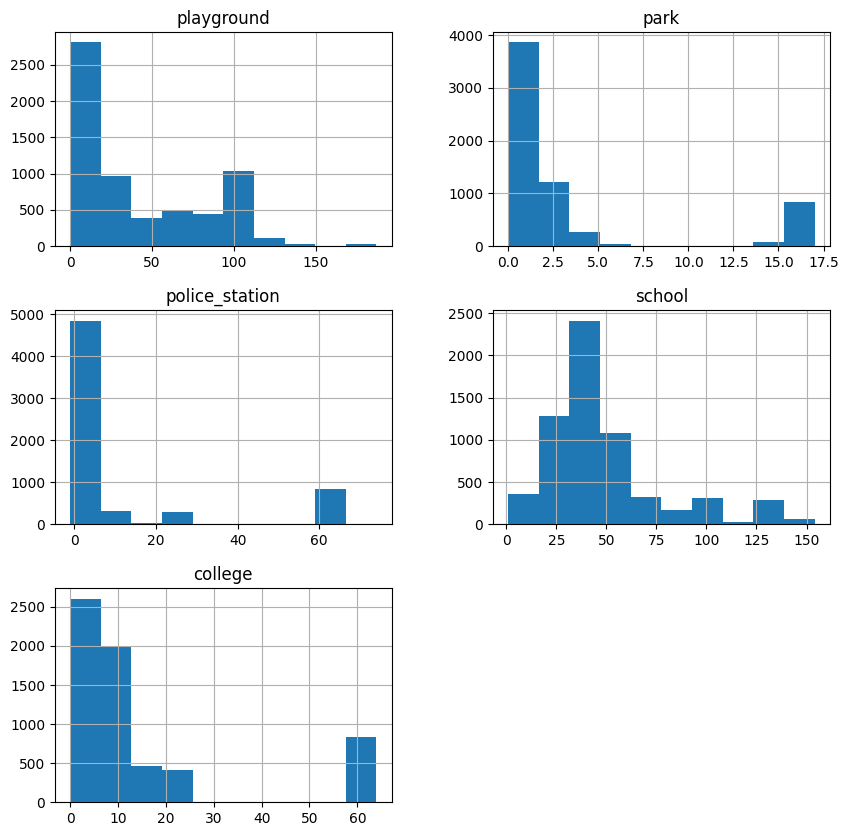

In [28]:
#crimes per tempat spesifik --> park, police_station, playground
place_cols = [
    "playground", "park", "police_station", "school", "college"]

df[place_cols].hist(figsize=(10,10))
plt.show()

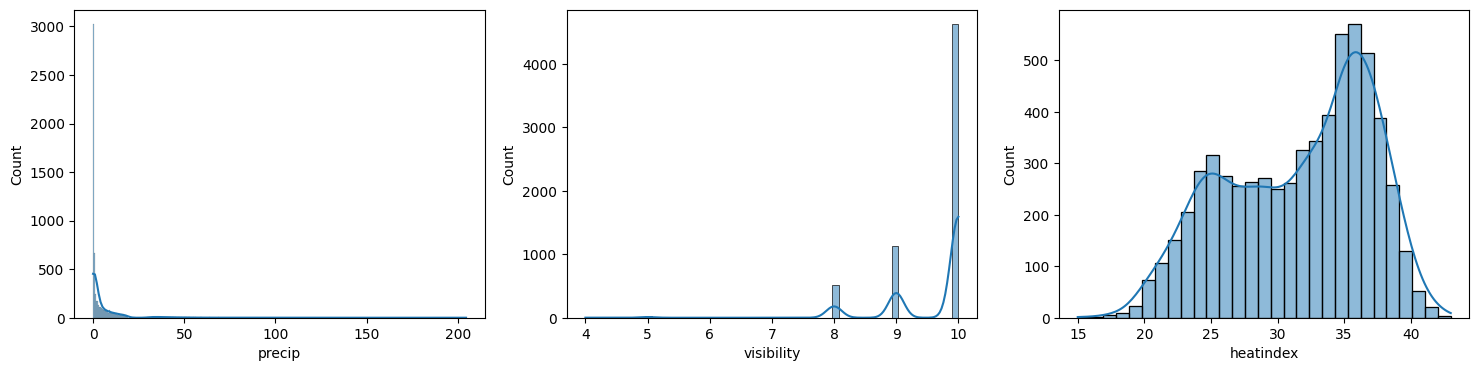

In [29]:
fig, ax = plt.subplots(1,3, figsize=(18,4))
sns.histplot(df["precip"], kde=True, ax=ax[0])
sns.histplot(df["visibility"], kde=True, ax=ax[1])
sns.histplot(df["heatindex"], kde=True, ax=ax[2])
plt.show()

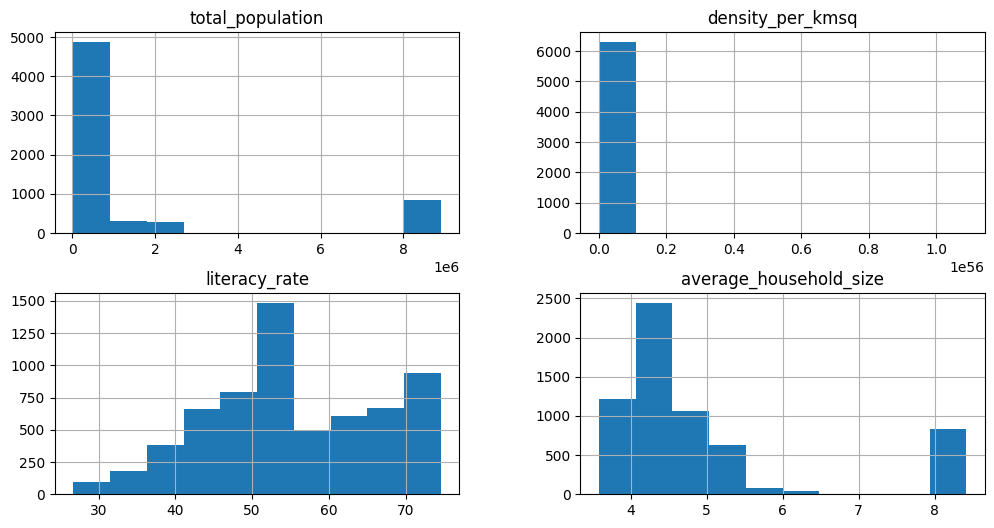

In [30]:
#cek distribusi shape data demografis

demo_cols = [
    "total_population", "density_per_kmsq",
    "literacy_rate", "average_household_size"]

df[demo_cols].hist(figsize=(12,6))
plt.show()

In [31]:
crime_by_district = df["incident_district"].value_counts()

crime_by_district.head(10)

#crime in dhaka bisa paling banyak karena populasinya paling gede --> jadi datanya harus di normalisasi misalnya jadi crime rate
#dibandingin crime count yaitu jumlah crime per total populasi di areaanya
#crime rate itu standardise berapa jumlah crime per set berapa orang, misalnya 100000

,count
incident_district,
dhaka,1391
chattogram,455
mymensingh,244
jashore,233
dinajpur,186
narayanganj,161
gazipur,158
bogura,157
pabna,153


In [32]:
#jadi standardize per 100 000 orang

crime_rate = (
    df.groupby("incident_district")
      .agg(
          crime_count=("crime", "count"),
          population=("total_population", "mean")
      )
)

crime_rate["crime_per_100k"] = (
    crime_rate["crime_count"] / crime_rate["population"] * 100000
)

crime_rate.sort_values("crime_per_100k", ascending=False)

#hasilnya beda, paling banyak crime_ratenya di bandarban
#maka crime rate yang sangat tinggi di Dhaka hanya karena jumlah populasi

,crime_count,population,crime_per_100k
incident_district,,,
bandarban,68,69975.294118,97.177155
dinajpur,186,269548.069892,69.004389
pirojpur,92,173886.836957,52.907973
jashore,233,460358.622318,50.612716
mymensingh,244,508341.176230,47.999259
...,...,...,...
sherpur,13,237036.692308,5.484383
shariatpur,11,201114.909091,5.469510
kurigram,10,184743.500000,5.412910


In [62]:
#cek jumlah fasilitas di bandarban, bandingin sama tempat" lain
facility_cols = [
    "school", "college", "playground", "park",
    "religious_institution", "police_station"
]

df.groupby("incident_district")[facility_cols].mean().loc["bandarban"]

,bandarban
school,36.764706
college,0.411765
playground,14.882353
park,1.529412
religious_institution,135.617647
police_station,3.676471


In [34]:
df[facility_cols].mean()

,0
school,49.379004
college,15.392959
playground,40.153346
park,3.381541
religious_institution,1231.301459
police_station,11.714082


In [35]:
df.groupby("incident_district")[[
    "male_population",
    "female_population",
    "gender_ration",
    "density_per_kmsq",
    "literacy_rate"
]].mean().loc["bandarban"]


,bandarban
male_population,3.668859e+04
female_population,3.329200e+04
gender_ration,1.100882e+02
density_per_kmsq,2.345096e+23
literacy_rate,3.510882e+01


In [36]:
#karena nilai density_per_kmsq sangat besar --> unnatural
#beresiko saat nanti membuat model kmeans
# kita log function variabelnya

df["density_per_kmsq"] = np.log1p(df["density_per_kmsq"])

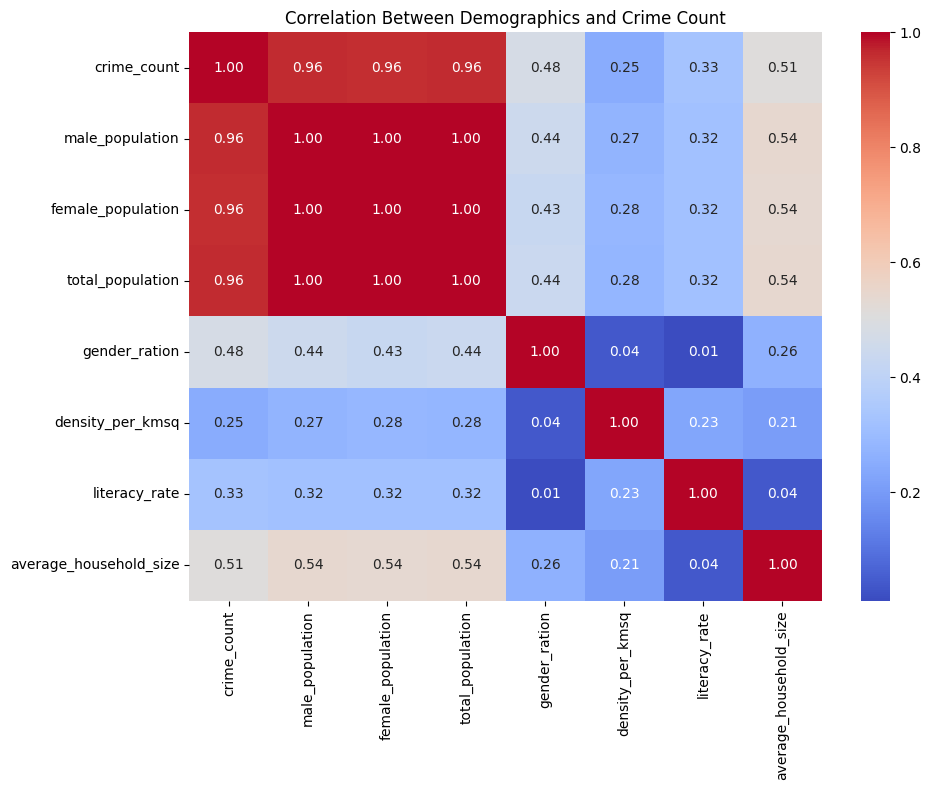

In [37]:
#bikin heatmap buat liat korelasi, demografik sama crime count

demo_df = (
    df.groupby("incident_district")
      .agg(
          crime_count=("crime", "count"),
          male_population=("male_population", "mean"),
          female_population=("female_population", "mean"),
          total_population=("total_population", "mean"),
          gender_ration=("gender_ration", "mean"),
          density_per_kmsq=("density_per_kmsq", "mean"),
          literacy_rate=("literacy_rate", "mean"),
          average_household_size=("average_household_size", "mean")
      )
)

plt.figure(figsize=(10,8))
sns.heatmap(
    demo_df.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)
plt.title("Correlation Between Demographics and Crime Count")
plt.tight_layout()
plt.show()


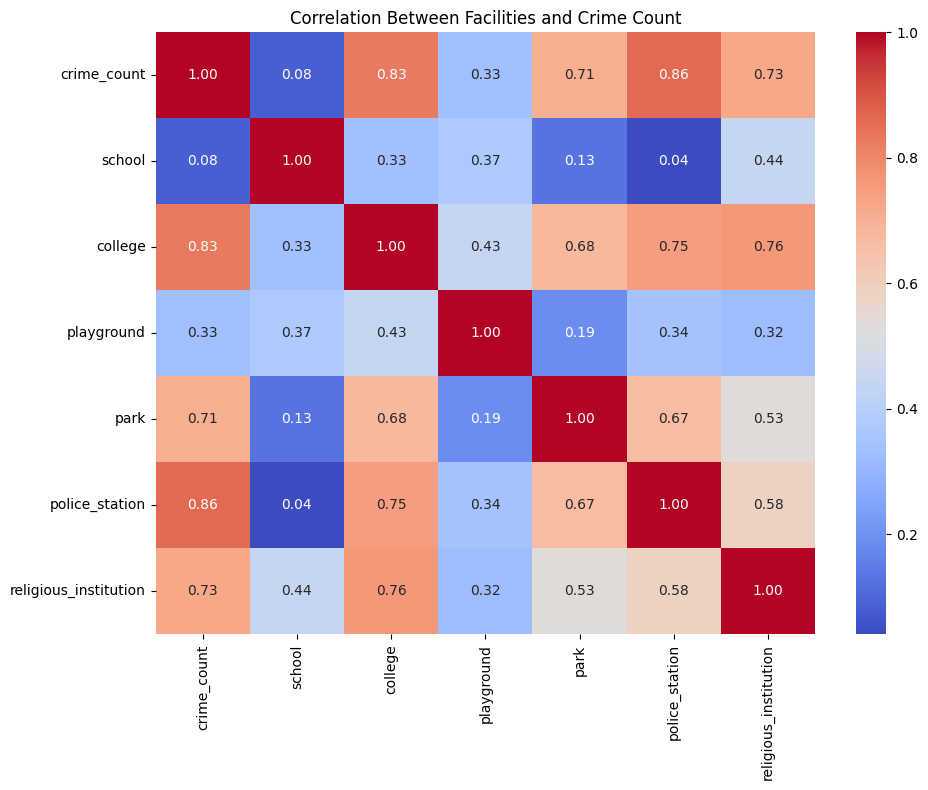

In [63]:
#heatmap facilities and crime

facility_df = (
    df.groupby("incident_district")
      .agg(
          crime_count=("crime", "count"),
          school=("school", "mean"),
          college=("college", "mean"),
          playground=("playground", "mean"),
          park=("park", "mean"),
          police_station=("police_station", "mean"),
          religious_institution=("religious_institution", "mean")
      )
)

plt.figure(figsize=(10,8))
sns.heatmap(
    facility_df.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)
plt.title("Correlation Between Facilities and Crime Count")
plt.tight_layout()
plt.show()


### KESIMPULAN EDA

FREQUENCY table untuk Crimes di setiap Categorical Feature
MOST CRIMES HAPPEN IN
- incident_weekday: Tuesday (971)
- park_of_the_day: Night (3151)
- incident_district: Dhaka(1391)
- incident_division: dhaka(1955)
- season: rainy(2722)
- crime: bodyfound(1476)

- crime di bulan 6 --> Juni sangat tinggi (bulan" liburan sekolah)
- crime di bulan 12 --> december paling rendah
- crime lebih banyak di weekdays (jam sibuk pekerjaan)

MENGAPA CRIME DI DHAKA SANGAT TINGGI

crime in dhaka bisa paling banyak karena populasinya paling gede --> jadi proporsi crimenya jauh menunjang tempat" lain

datanya harus di normalisasi misalnya jadi crime rate dibandingin crime count yaitu jumlah crime per total populasi di areaanya. crime rate itu standardise berapa jumlah crime per set berapa orang, misalnya 100000

setelah di normalisasi --> paling banyak crime_ratenya di bandarban. maka crime rate yang sangat tinggi di Dhaka hanya karena jumlah populasi


PERBANDINGAN FACILITIES BANDARBAN DENGAN RATA" TEMPAT LAIN

BANDARBAN:
- school                     3.441176
- college                    0.411765
- playground                14.882353
- park                       1.529412
- religious_institution    135.617647
- police_station             3.676471

much fewer educational facilities, school, college --> less accessible

way less religious_institutions and police stations compared to the average

AVERAGE:
- school                     49.379004
- college                    15.392959
- playground                 40.153346
- park                        3.381541
- religious_institution    1231.301459
- police_station             11.714082


HEATMAP Demografi & Crime Count
- population data: male, female total (0.96) strong positive correlation
- average household size (0.51) considerable positive corr
- gender ration (0.48) weak positive corr


HEATMAP Facilities & Crime Count
- Police stations: 0.86 strong positive corr --> more crime reported to stations
- college: 0.83 strong positive corr --> place with many people ages 18 - 24
- religious institutions: 0.73 strong positive corr
- park: 0.71 strong positive corr --> many kids are more vulnerable to crime
- playground: 0.33 weak positive correlation
- school: 0.08 little to no correlation

### Tranining K-means

In [64]:
df["density_per_kmsq"] = np.log1p(df["density_per_kmsq"]) # data density di atas unit e+23
# data terlalu besar --> risky untuk k means yang calculate euclidean distance
# bisa dominasi scale

In [40]:
num_cols = [
    "incident_month", "incident_week", "weekend",
    "precip", "visibility", "heatindex",
    "male_population", "female_population", "total_population",
    "gender_ration", "average_household_size",
    "density_per_kmsq", "literacy_rate",
    "religious_institution", "playground", "park",
    "police_station", "school", "college"
]

cat_cols = [
    "incident_weekday", "part_of_the_day",
    "incident_district", "incident_division", "season"
]

In [41]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(drop="first", sparse_output=False), cat_cols)
    ]
)

#karena Kmeans model lebih bagus menggunakan data yang distribusinya ~ normal karena algoritma yang euclidean distance based
#maka tanpa scaling fitur" yang lebih jauh atau lebih besar bervariasi akan mendominasi kalkulasi jarak euclidean --> model kurang akurat
#standard scaler --> teknik buat preprocessing variabel numeric, ubah jadi mean = 0, standarddev = 1 --> ~ normal dist
#onehot encoder --> mengubah categorical data (nominal) ke format numerical, binary (angka" 0 & 1)
#kekurangan onehot --> curse of dimensionality --> kalau fitur kebanyakan unique values

In [42]:
X = df[num_cols + cat_cols]

X_processed = preprocessor.fit_transform(X)

inertias = []
silhouettes = []

K_range = range(2, 9)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_processed)
    inertias.append(kmeans.inertia_)
    silhouettes.append(silhouette_score(X_processed, labels))


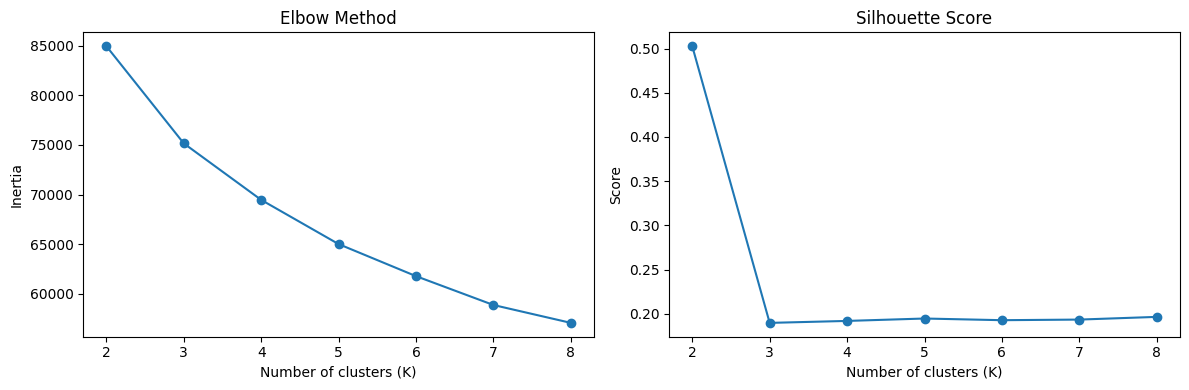

In [43]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(K_range, inertias, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")

plt.subplot(1,2,2)
plt.plot(K_range, silhouettes, marker="o")
plt.title("Silhouette Score")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Score")

plt.tight_layout()
plt.show()


In [44]:
kmeans_final = KMeans(n_clusters=3, random_state=42, n_init=10)
df["cluster"] = kmeans_final.fit_predict(X_processed)


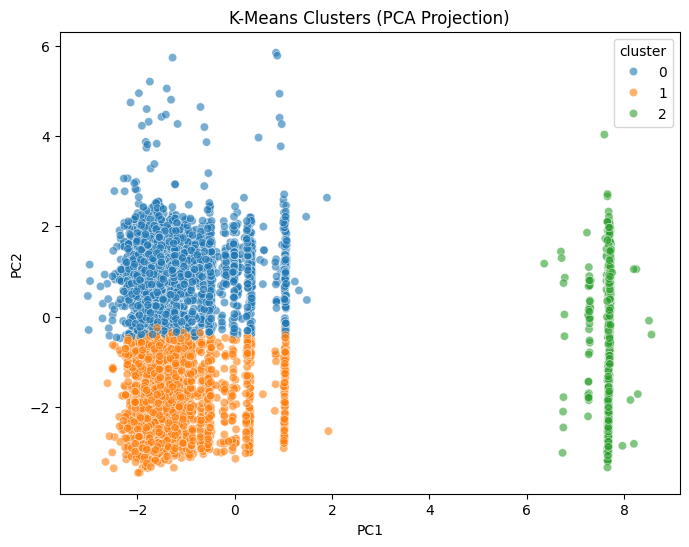

In [45]:
#PCA harus dipake karena dimensionality datanya tinggi --> banyak fiturnya

from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_processed)

df["PC1"] = X_pca[:, 0]
df["PC2"] = X_pca[:, 1]

plt.figure(figsize=(8,6))
sns.scatterplot(
    x="PC1", y="PC2",
    hue="cluster",
    palette="tab10",
    data=df,
    alpha=0.6
)
plt.title("K-Means Clusters (PCA Projection)")
plt.show()


### KESIMPULAN MODEL BUILDING

fitur" numerical dan categorical dipisah terlebih dahulu sebelum preprocessing dengan standard scaler untuk numerical columns untuk membuatnya ~ normal (mean~ 0, standard dev~1). and categorical columns with OneHotEncoder --> turns into a series of binary matrix --> berguna untuk kmeans model

- karena Kmeans model lebih bagus menggunakan data yang distribusinya ~ normal karena algoritma yang euclidean distance based
- maka tanpa scaling fitur" yang lebih jauh atau lebih besar bervariasi akan mendominasi kalkulasi jarak euclidean --> model kurang akurat
- standard scaler --> teknik buat preprocessing variabel numeric, ubah jadi mean = 0, standarddev = 1 --> ~ normal dist
- onehot encoder --> mengubah categorical data (nominal) ke format numerical, binary (angka" 0 & 1)
- kekurangan onehot --> curse of dimensionality --> kalau fitur kebanyakan unique values


K-Means Model di tune based on 2 metrics
1. elbow method
2. silhouette score

di grafik elbow method kami bisa melihat bahwa dip terbesar (penurunan terbesar) terjadi di cluster 2 sampai 3, setelah 3 clusters grafik menurun secara perlahan (melandai)

di grafik silhouette score hal yang sama terlihat secara lebih dramatis dimana penurunan number of clusters paling besar terjadi di 3 clusters, dan setelah 3 clusters score data relatif stabil(tidak banyak berubah)

maka number of clusters kita K = 3


PROJECTION

dimensionality dataset tinggi --> butuh menggunakan PCA untuk reduce dimensionality sebelum Cluster Projection

Data have a clear separation of 3 clusters with minimal overlapping/mixing

CLUSTER 0:
- PC1 = -2 - 1
- PC2 = 0 - 4

CLUSTER 1:
- PC1 = -2 - 1
- PC2 = -3 - 0

CLUSTER 2:
- PC1 = ~7.7
- PC2 = -4 - 2

PC1 captures the dominant variance in crime-related characteristics across districts, while PC2 represents secondary variation independent of PC1.

### Cluster Profiling

In [68]:
#untuk data numerical

cluster_profile_num = (
    df.groupby("cluster")[num_cols].mean().round(2))

cluster_profile_num


,incident_month,incident_week,weekend,precip,visibility,heatindex,male_population,female_population,total_population,gender_ration,average_household_size,density_per_kmsq,literacy_rate,religious_institution,playground,park,police_station,school,college
cluster,,,,,,,,,,,,,,,,,,,
0,7.93,33.64,0.26,4.91,9.46,33.68,267845.63,255174.30,523100.81,101.51,4.42,1.12,53.14,762.38,31.49,1.34,4.34,40.88,8.04
1,2.94,9.39,0.30,0.54,9.93,27.54,262043.94,250856.58,512952.72,100.91,4.47,1.13,52.68,772.53,30.65,1.24,4.45,39.42,7.92
2,6.24,25.51,0.27,2.41,9.66,31.99,4931802.00,3974237.00,8906039.00,125.00,8.42,1.22,73.66,4289.00,99.00,17.00,59.93,45.00,64.00


In [69]:
#untuk variabel kategorik

cluster_profile_cat = (
    df.groupby("cluster")[cat_cols]
      .agg(lambda x: x.mode()[0])
)

cluster_profile_cat

,incident_weekday,part_of_the_day,incident_district,incident_division,season
cluster,,,,,
0,wednesday,night,dhaka,dhaka,rainy
1,tuesday,night,dhaka,chattogram,hot
2,sunday,night,dhaka,dhaka,rainy


In [70]:
crime_dist = (
    df.groupby("cluster")["crime"]
      .value_counts(normalize=True)
      .rename("proportion")
      .reset_index())

crime_dist

,cluster,crime,proportion
0,0,bodyfound,0.239551
1,0,murder,0.216550
2,0,rape,0.201683
3,0,assault,0.169144
4,0,kidnap,0.101262
5,0,robbery,0.071809
6,1,murder,0.291405
7,1,bodyfound,0.205451
8,1,assault,0.164046
9,1,rape,0.153564


In [49]:
df.groupby('cluster')['incident_division'].agg(lambda x: x.value_counts().index[0])

,incident_division
cluster,
0,dhaka
1,chattogram
2,dhaka


### KESIMPULAN CLUSTER PROFILING

DARI CORRELASI

- population data: male, female total (0.96) strong positive correlation
- average household size (0.51) considerable positive corr
- gender ration (0.48) weak positive corr
- Police stations: 0.86 strong positive corr --> more crime reported to stations
- college: 0.83 strong positive corr --> place with many people ages 18 - 24
- religious institutions: 0.73 strong positive corr
- park: 0.71 strong positive corr --> many kids are more vulnerable to crime


PC1 --> dominant variance in crime-related characteristics across districts
PC2 represent --> secondary variation independent of PC1


COMMON VALUES CLUSTERS(0, 1, 2)
- incident district: dhaka
- part of the day: night


CLUSTER 0:
- PC1 = -2 - 1
- PC2 = 0 - 4
- season: rainy
- incident division: dhaka
- paling banyak crime: bodyfound
- Literacy rate ~ 53
- Religious institution ~ 762
- Police station ~ 4.3


CLUSTER 1:
- PC1 = -2 - 1
- PC2 = -3 - 0
- season: hot
- incident division: chattogram
- paling banyak crime: murder
- Literacy rate ~ 53
- Religious institution ~  773
- Police station ~ 4.5


CLUSTER 2:
- PC1 = ~7.7
- PC2 = -4 - 2
- season: rainy
- incident division: dhaka
- paling banyak crime: bodyfound
- Literacy rate ~ 74
- Religious institution ~ 4 289
- Police station ~ 60


